In [31]:
import anndata as ad

st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/spatial/GSM9509174_breast_breast_B1_B1_3_rctd_annotated.h5ad')



In [6]:
st_data.obs['cell_type'].unique()

['natural T-regulatory cell', 'plasma cell', 'cytotoxic T cell', 'malignant cell', 'capillary endothelial cell', ..., 'macrophage', 'CD4-positive, alpha-beta memory T cell', 'plasmacytoid dendritic cell', 'mast cell', 'fibroblast of breast']
Length: 15
Categories (15, object): ['mast cell', 'smooth muscle cell', 'macrophage', 'natural killer cell', ..., 'malignant cell', 'capillary endothelial cell', 'fibroblast of lung', 'fibroblast of breast']

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


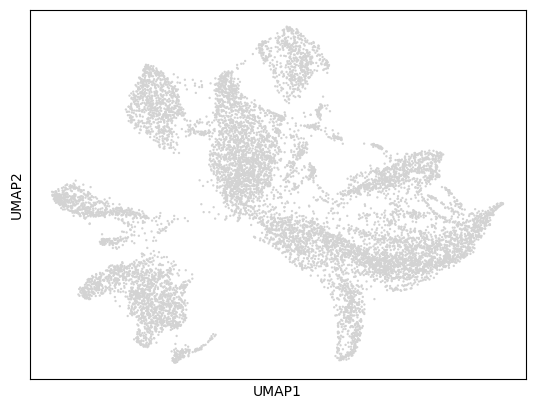

In [16]:
import scanpy as sc
adata = st_data.copy()

# Assume 'adata' is your AnnData object with a raw count matrix in adata.X
# 1. Normalize total counts per cell (default target sum = 10,000)
# sc.pp.normalize_total(adata, target_sum=1e4)

# 2. Log-transform the data
sc.pp.log1p(adata)

# 3. Identify highly variable genes
# sc.pp.highly_variable_genes(adata, min_mean=0.012, max_mean=3, min_disp=0.5)
# adata = adata[:, adata.var.highly_variable]

# 4. Scale data to unit variance and zero mean
sc.pp.scale(adata, max_value=10)

# 5. Run Principal Component Analysis (PCA)
sc.tl.pca(adata, svd_solver="arpack",n_comps=50)

# 6. Compute the neighborhood graph
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=40)

# 7. Run UMAP
sc.tl.umap(adata)

# Plot the UMAP result
sc.pl.umap(adata)


In [18]:
adata = adata[adata.obs.sort_values(by='cell_type').index]

In [32]:
adata = st_data.copy()

In [35]:
cts = sorted(adata.obs['harmony_cell_type'].unique())

In [37]:
adata

AnnData object with n_obs × n_vars = 108069 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type'
    var: 'feature_name', 'feature_type', 'genome', 'id', 'name', 'feature'
    uns: 'rctd_cell_type_names', 'rctd_class_df', 'rctd_postprocessing', 'rctd_run_metadata', 'source_h5_files'
    obsm: 'X_pca_harmony', 'X_pca_harmony_GSM9509174_breast_breast_B1_B1_3_rctd', 'rctd_w

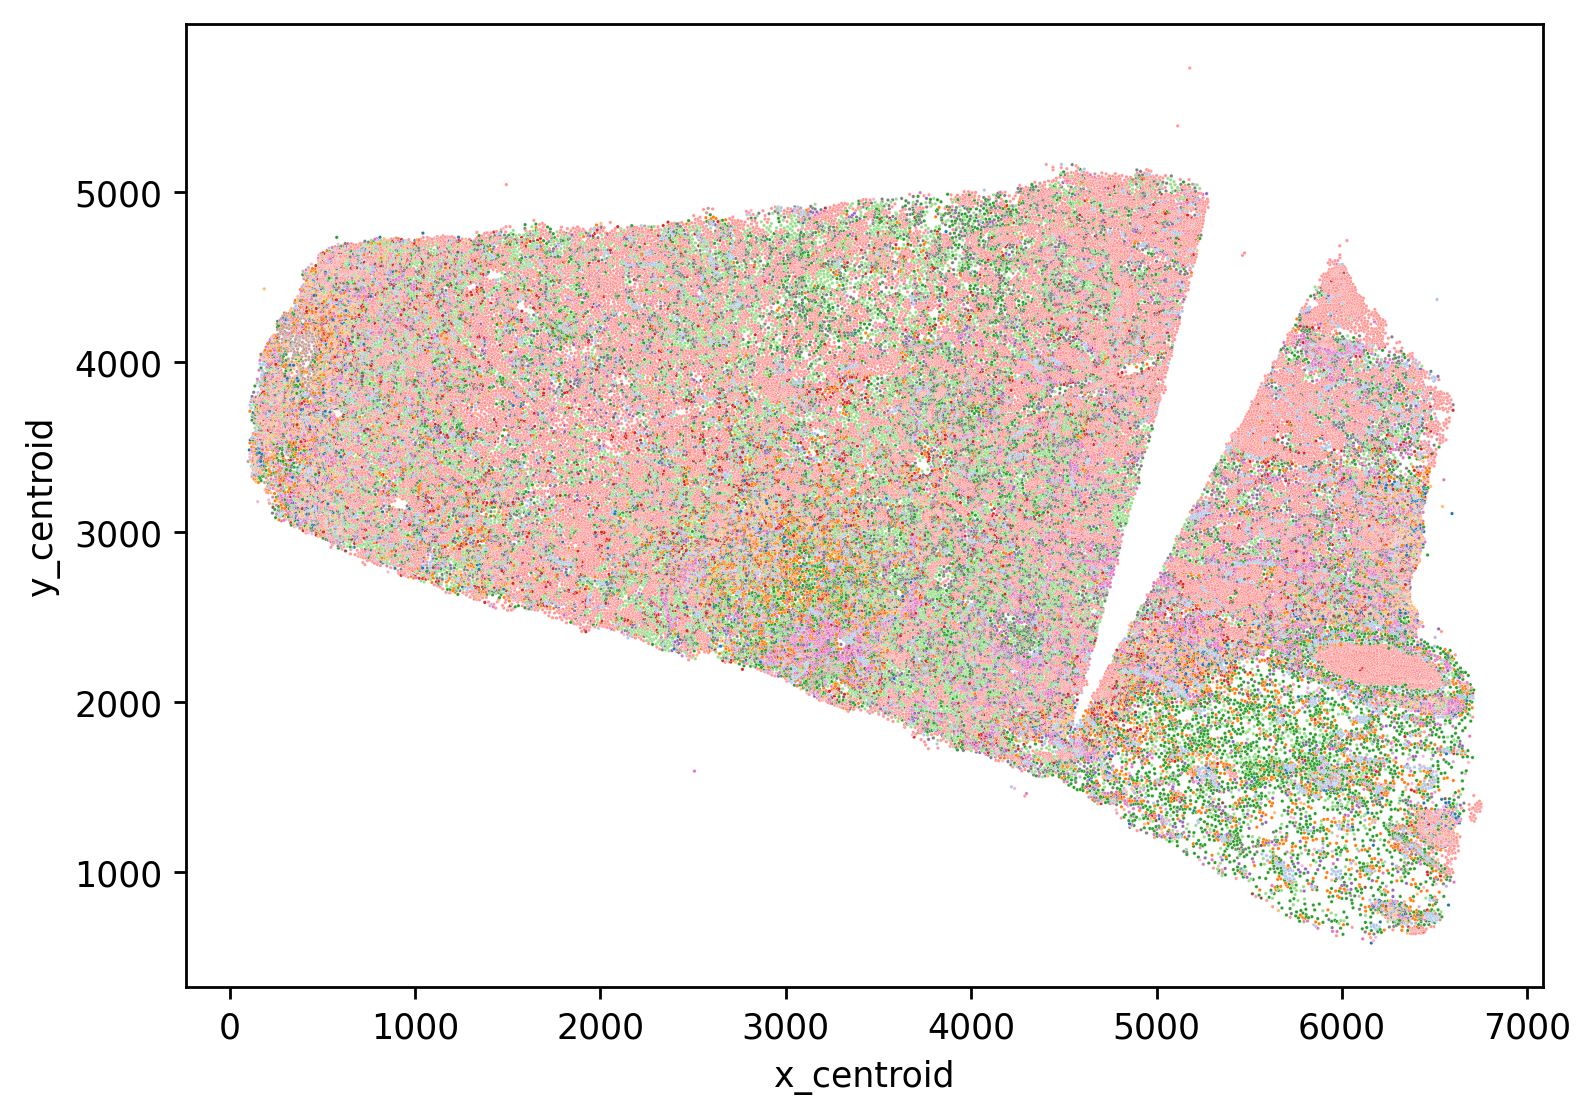

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(7,5),dpi=250)
ax = sns.scatterplot(x=adata.obs['x_centroid'],y=adata.obs['y_centroid'],s=1,hue=adata.obs['harmony_cell_type'],hue_order=cts,palette='tab20',ax=ax,legend=False)

# handles, labels = ax.get_legend_handles_labels()

# # 2. Sort handles and labels alphabetically by label
# sorted_pairs = sorted(zip(labels, handles), key=lambda t: t[0])
# sorted_labels, sorted_handles = zip(*sorted_pairs)

# print(sorted_labels)
# # 3. Apply the sorted lists to the subplot legend
# ax.legend(sorted_handles, sorted_labels)
# ax.legend(bbox_to_anchor=(1,1.05),markerscale=5)


In [25]:
adata.obs['rctd_spot_class'].value_counts()

rctd_spot_class
singlet              29518
doublet_certain       3271
reject                 513
doublet_uncertain      175
rctd_filtered           17
Name: count, dtype: int64

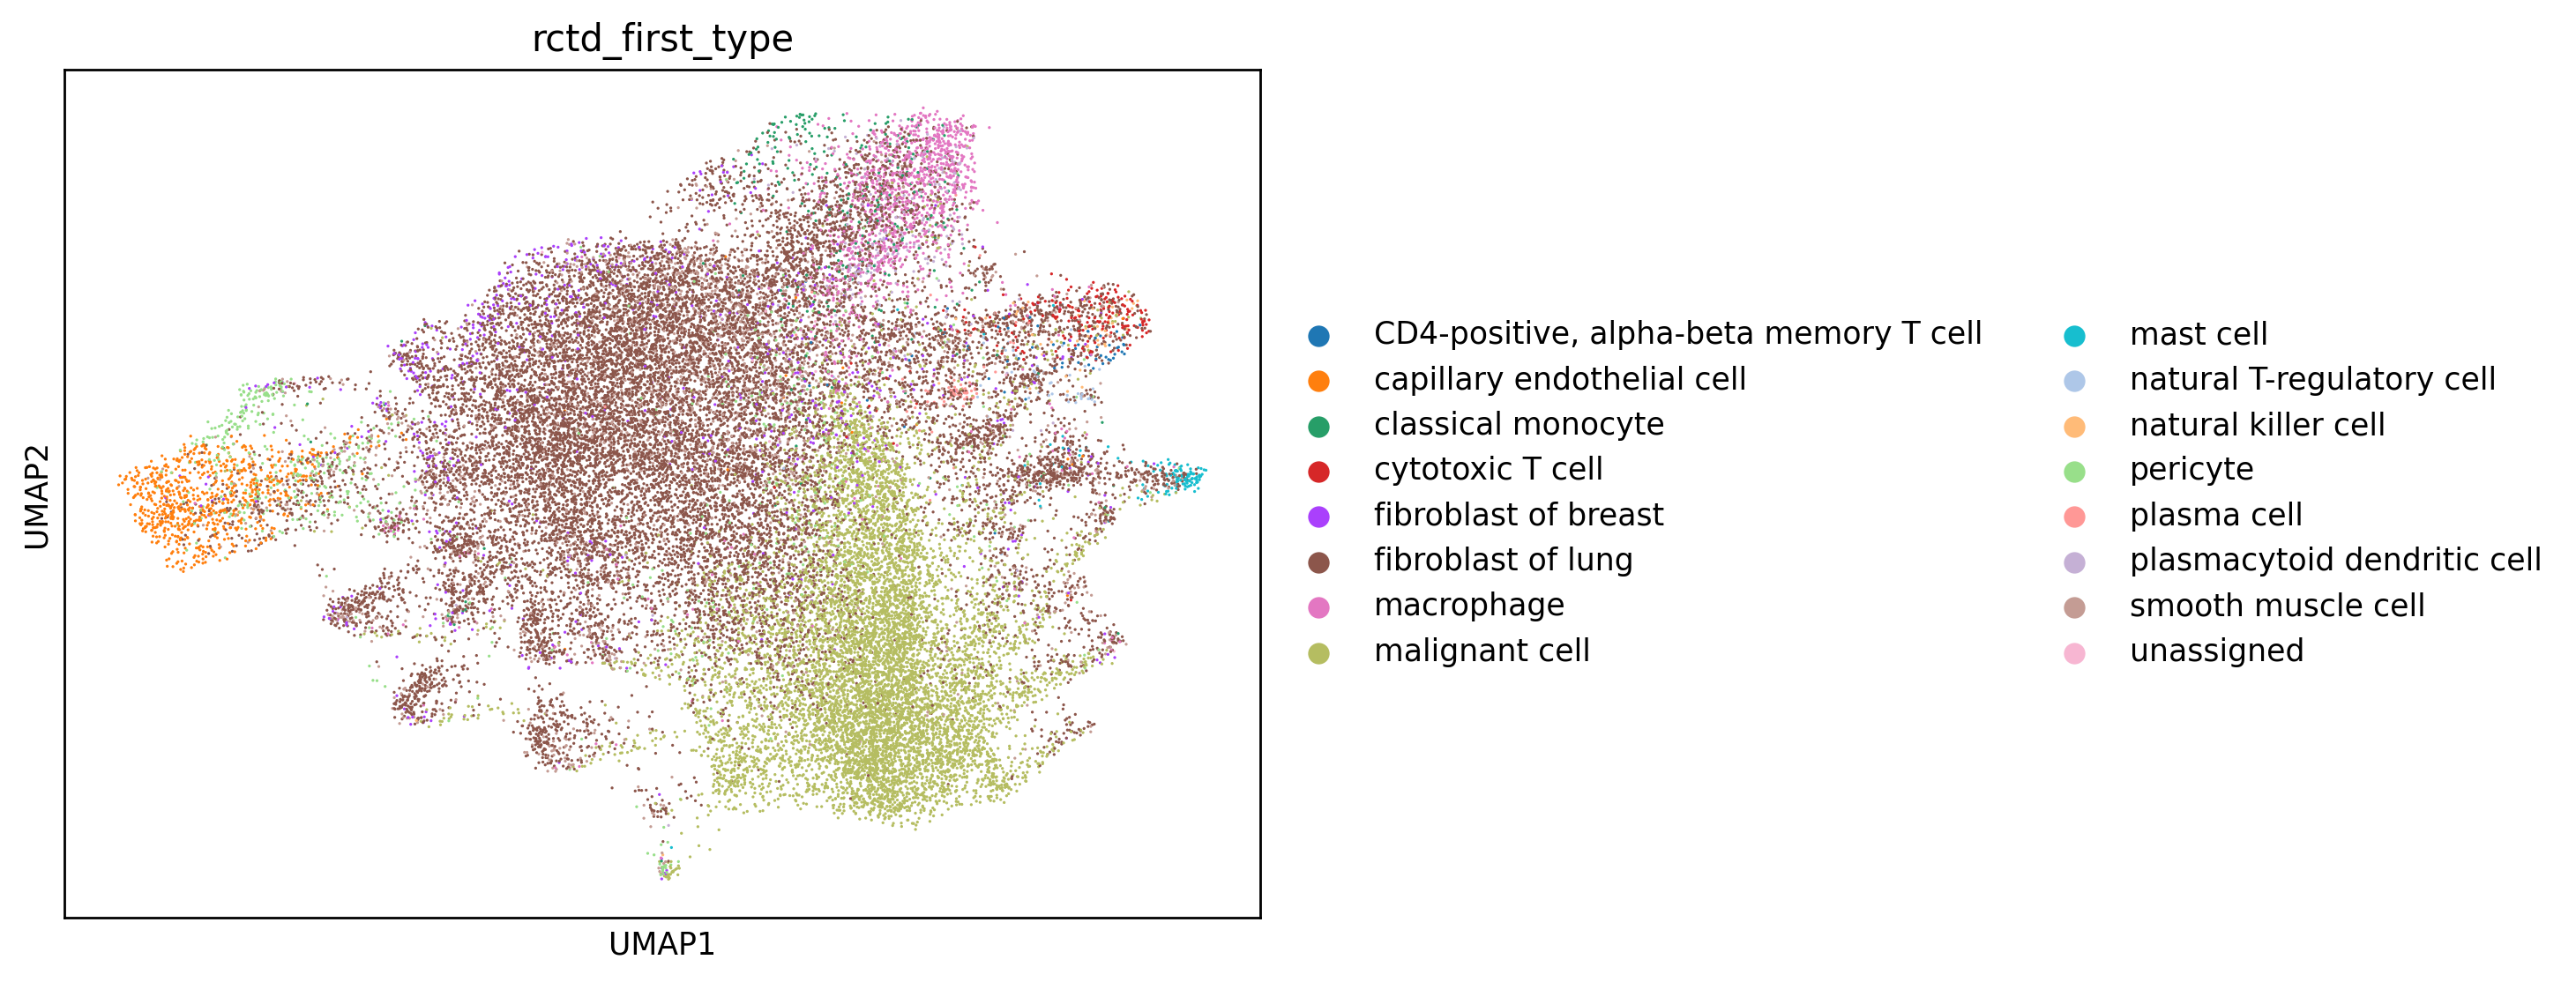

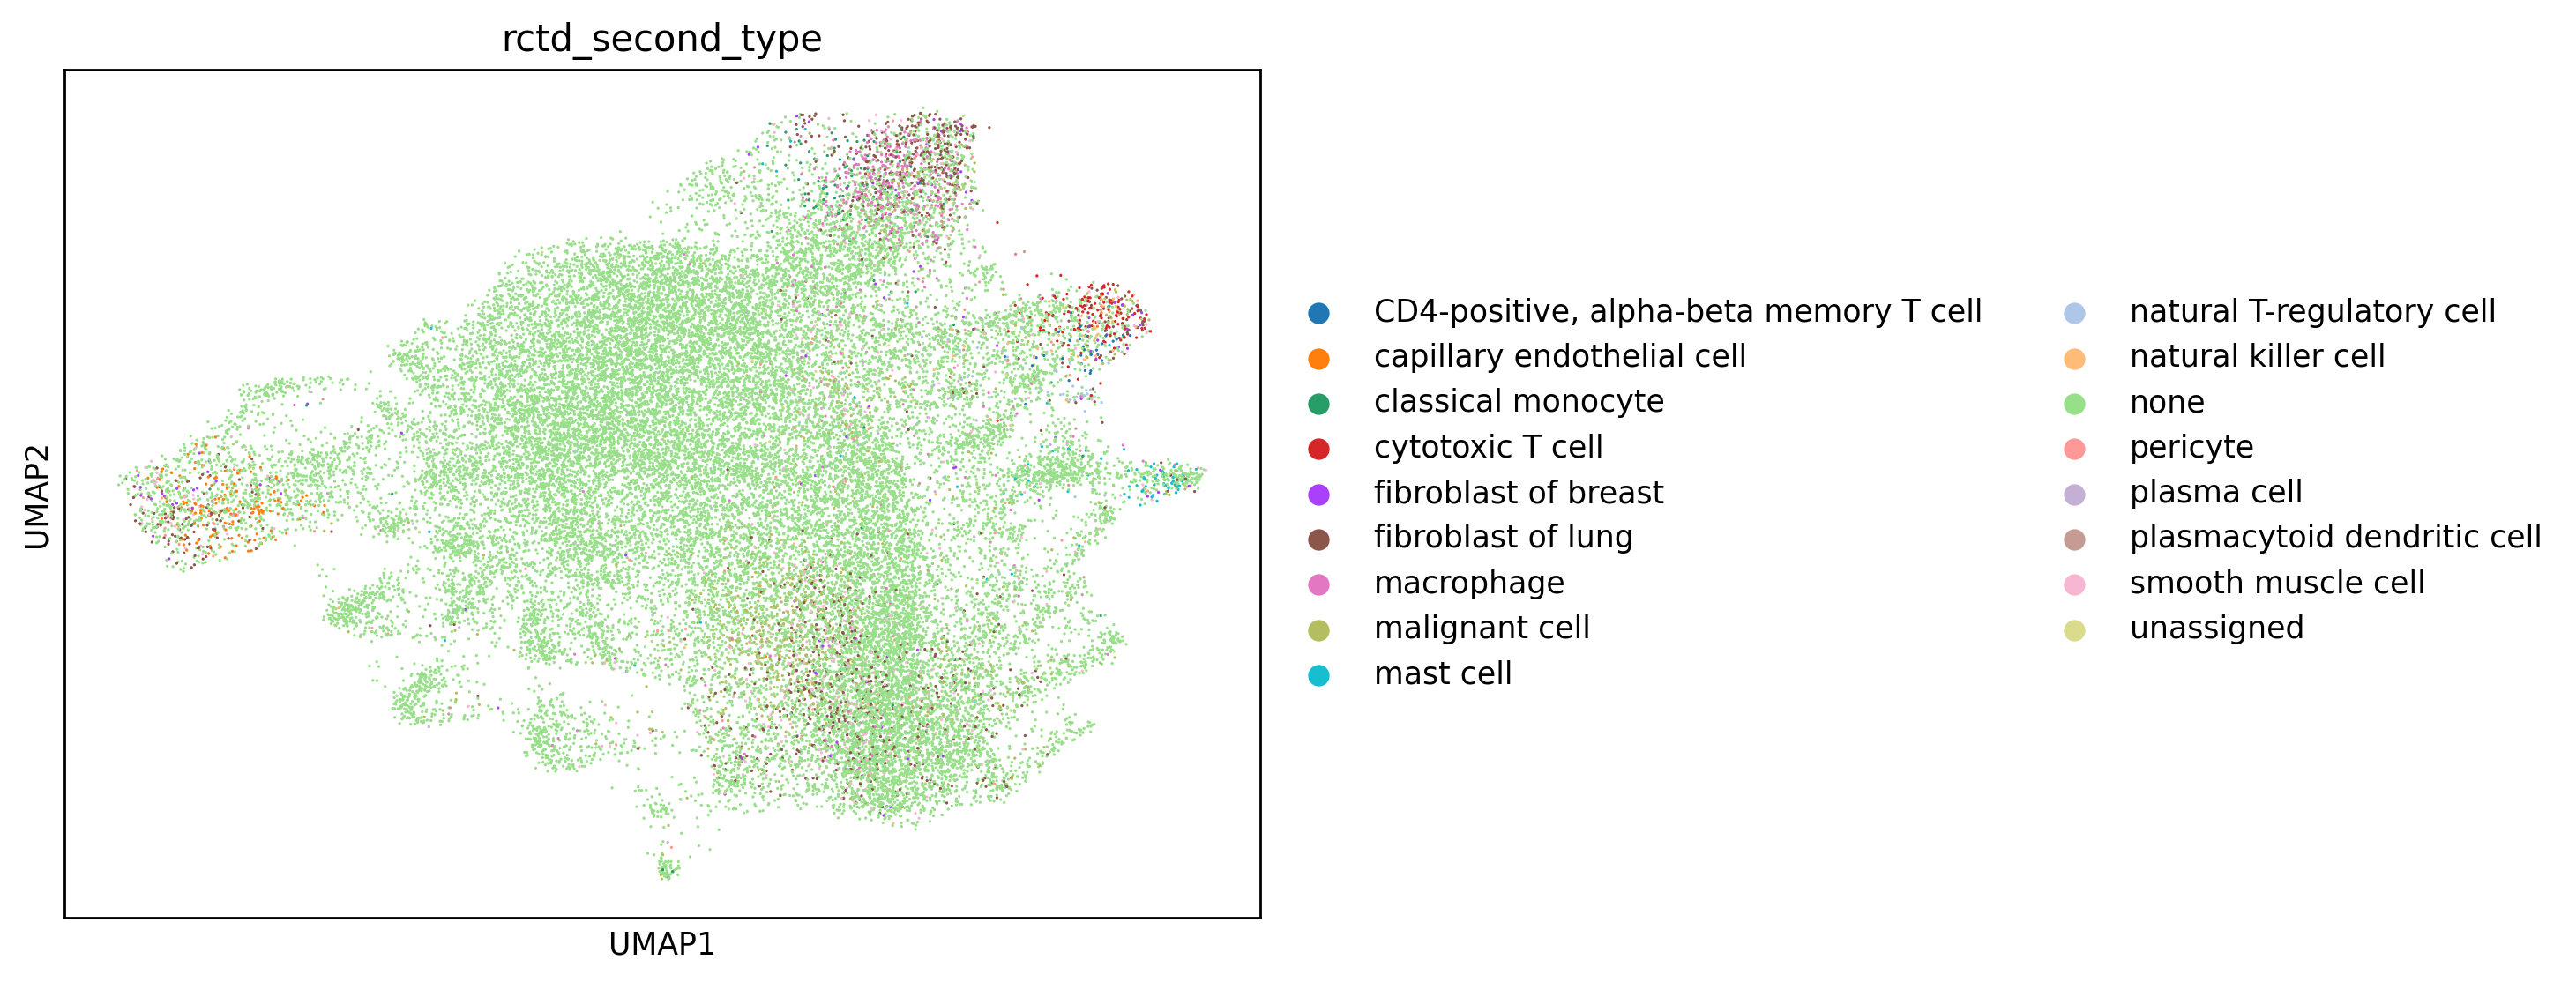

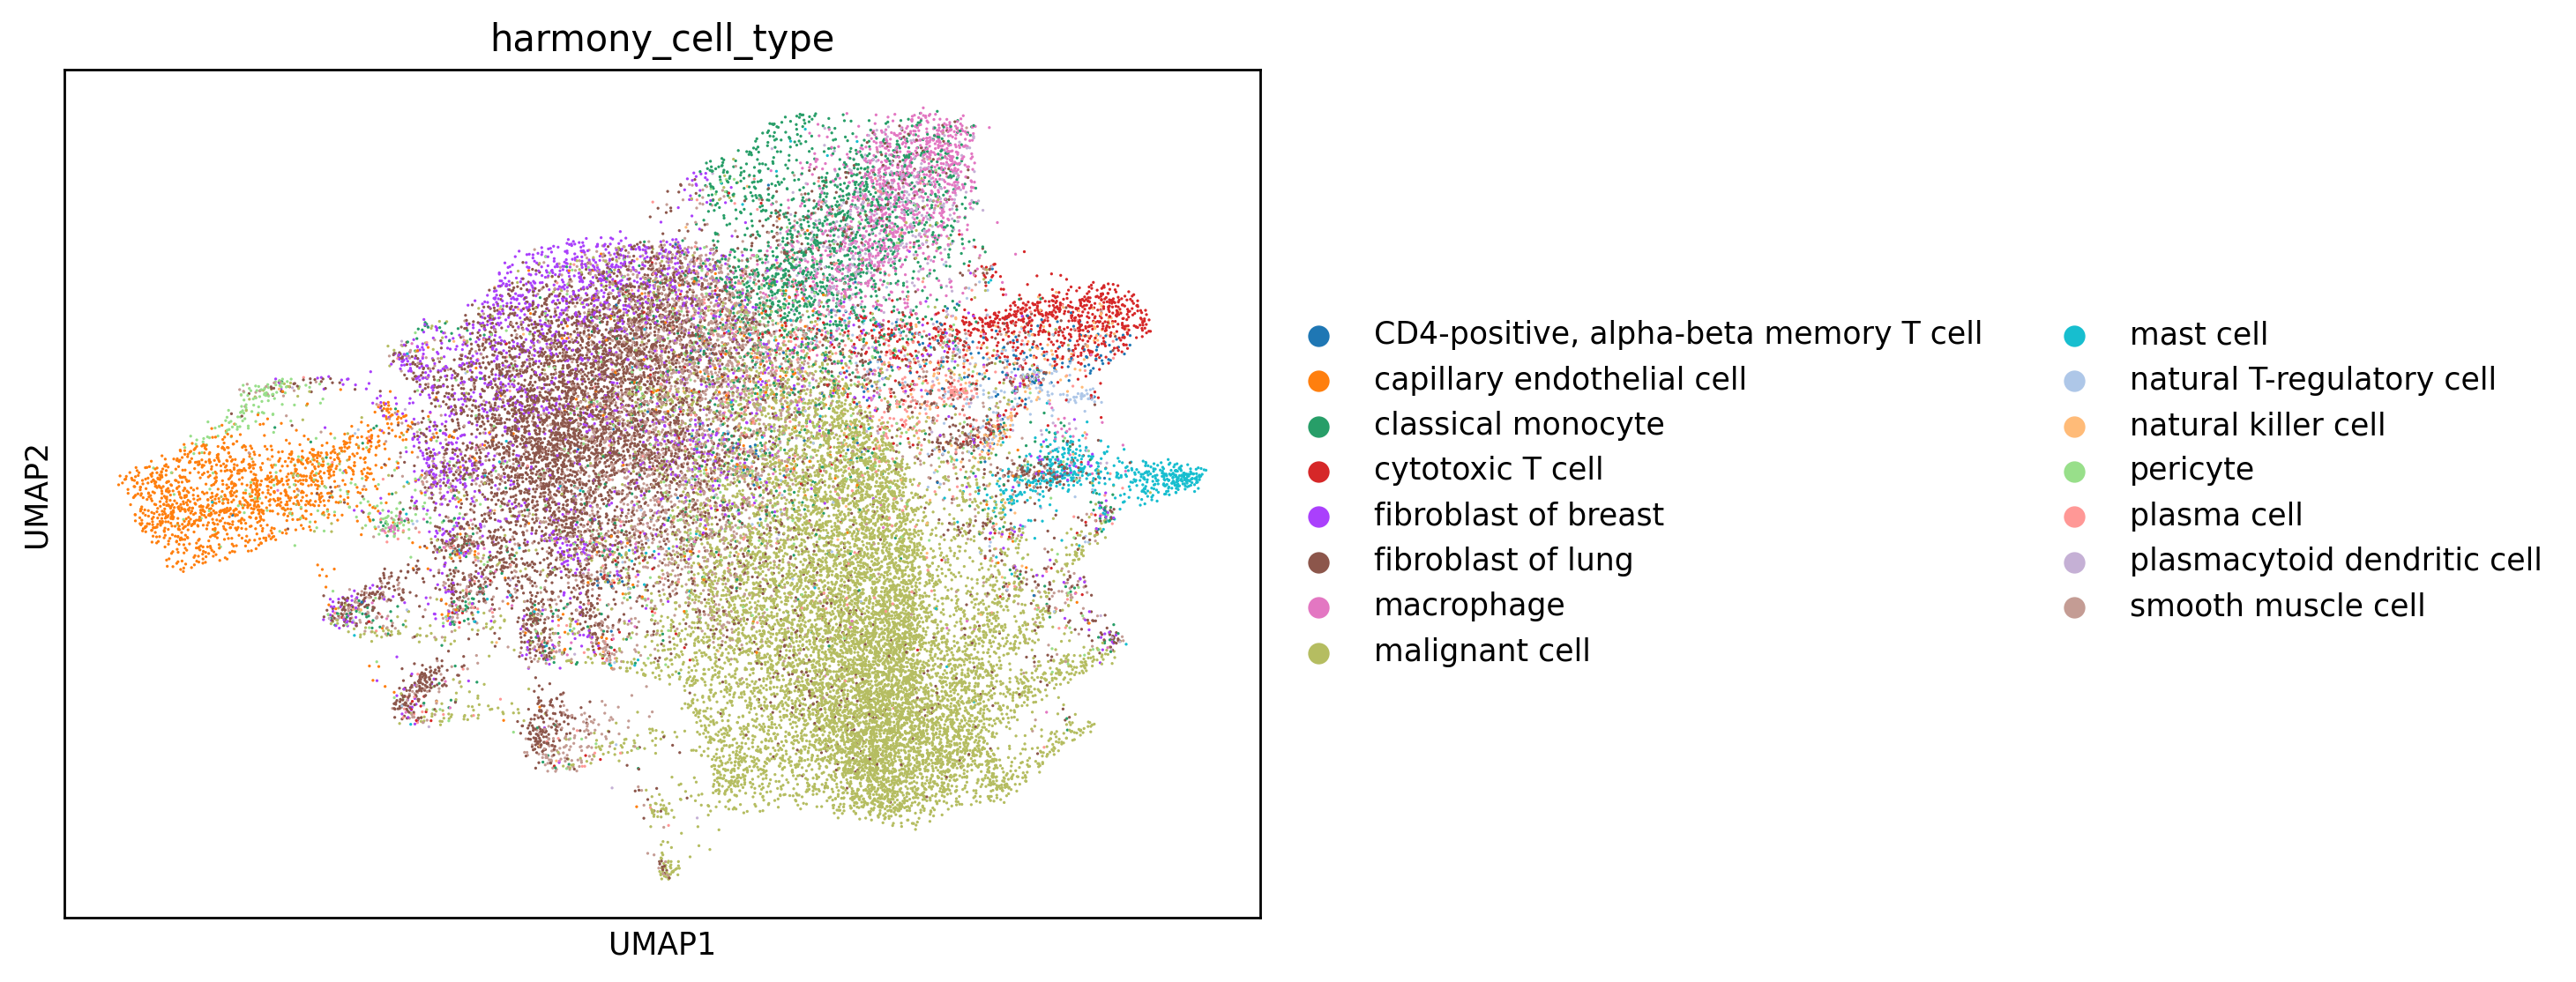

In [29]:
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(7,5),dpi=250)
sc.pl.umap(adata,color='rctd_first_type',ax=ax)
fig,ax = plt.subplots(figsize=(7,5),dpi=250)
sc.pl.umap(adata,color='rctd_second_type',ax=ax)
fig,ax = plt.subplots(figsize=(7,5),dpi=250)
sc.pl.umap(adata,color='harmony_cell_type',ax=ax)